# Assignment 2b: Edge Detection, Noise, and Denoising

This notebook reads `assignment-1-data/blox.jpg` and saves edge, noise, and denoising results under `output/part2b_edges/`.

In [1]:
%matplotlib inline

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

## Part 2b: Edge Detection, Noise, and Denoising

Load `blox.jpg` as grayscale. Extract edges and regions using `cv2.Sobel()`, `cv2.Canny()`, `cv2.threshold()`, and `cv2.inRange()`. Then add zero-mean Gaussian noise at 20 dB and 10 dB PSNR, and evaluate how noise and denoising filters (`cv2.GaussianBlur`, `cv2.medianBlur`, `cv2.bilateralFilter`) affect edge detection.

In [2]:
edge_input_path = Path("assignment-1-data/blox.jpg")
edge_output_dir = Path("output/part2b_edges")
edge_output_dir.mkdir(parents=True, exist_ok=True)

blox_gray = cv2.imread(str(edge_input_path), cv2.IMREAD_GRAYSCALE)
if blox_gray is None:
    raise FileNotFoundError(f"Could not read {edge_input_path}")
print(f"BloX grayscale range: {blox_gray.min()} to {blox_gray.max()}")

BloX grayscale range: 0 to 252


Clean Canny edge coverage: 5.0%
Clean Sobel threshold coverage: 10.0%


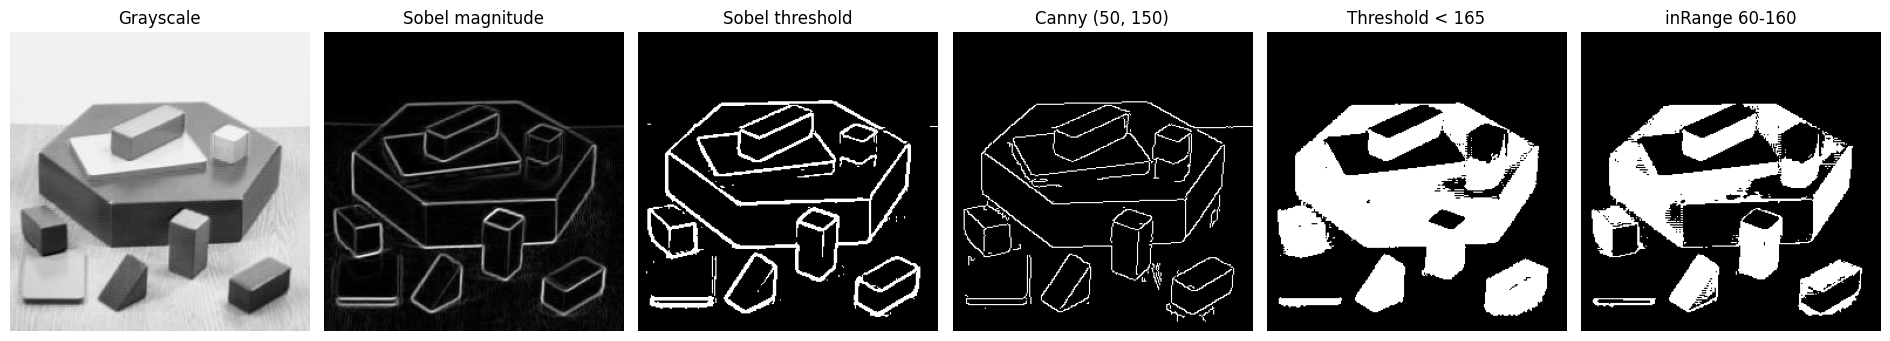

In [3]:
def analyze_edges(gray_image, low_canny=50, high_canny=150):
    """Run Sobel, Canny, inverse threshold, and gray-band extraction on an 8-bit image."""
    sobel_x = cv2.Sobel(gray_image, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray_image, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = cv2.magnitude(sobel_x, sobel_y)

    mag_max = float(magnitude.max())
    mag_uint8 = np.rint(magnitude * (255.0 / mag_max)).clip(0, 255).astype(np.uint8) if mag_max > 0 else np.zeros_like(gray_image)
    _, sobel_binary = cv2.threshold(magnitude, 110, 255, cv2.THRESH_BINARY)
    canny_edges = cv2.Canny(gray_image, low_canny, high_canny)
    _, dark_regions = cv2.threshold(gray_image, 165, 255, cv2.THRESH_BINARY_INV)
    gray_band = cv2.inRange(gray_image, 60, 160)

    return {
        "magnitude": mag_uint8,
        "sobel_binary": sobel_binary.astype(np.uint8),
        "canny": canny_edges,
        "dark_regions": dark_regions,
        "gray_band": gray_band,
    }


def save_edge_result(name, result):
    cv2.imwrite(str(edge_output_dir / f"{name}_sobel_magnitude.png"), result["magnitude"])
    cv2.imwrite(str(edge_output_dir / f"{name}_sobel_binary.png"), result["sobel_binary"])
    cv2.imwrite(str(edge_output_dir / f"{name}_canny.png"), result["canny"])
    cv2.imwrite(str(edge_output_dir / f"{name}_dark_regions.png"), result["dark_regions"])
    cv2.imwrite(str(edge_output_dir / f"{name}_gray_band.png"), result["gray_band"])


clean_edges = analyze_edges(blox_gray)
save_edge_result("blox", clean_edges)
cv2.imwrite(str(edge_output_dir / "blox_grayscale.png"), blox_gray)

print(f"Clean Canny edge coverage: {100 * np.count_nonzero(clean_edges['canny']) / clean_edges['canny'].size:.1f}%")
print(f"Clean Sobel threshold coverage: {100 * np.count_nonzero(clean_edges['sobel_binary']) / clean_edges['sobel_binary'].size:.1f}%")

fig, axes = plt.subplots(1, 6, figsize=(19, 4))
panels = [
    (blox_gray, "Grayscale"),
    (clean_edges["magnitude"], "Sobel magnitude"),
    (clean_edges["sobel_binary"], "Sobel threshold"),
    (clean_edges["canny"], "Canny (50, 150)"),
    (clean_edges["dark_regions"], "Threshold < 165"),
    (clean_edges["gray_band"], "inRange 60-160"),
]
for axis, (pixels, title) in zip(axes, panels):
    axis.imshow(pixels, cmap="gray", vmin=0, vmax=255)
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

### Add white Gaussian noise at the requested PSNR levels

The exercise defines PSNR as $20 \log_{10}((I_{max} - I_{min}) / \sigma_n)$, so $\sigma_n = (I_{max} - I_{min}) / 10^{PSNR/20}$. Zero-mean Gaussian noise is generated using `np.random.normal()` and added to the image. The noisy values are clipped to $[0, 255]$ and formatted as standard 8-bit `uint8` images for OpenCV edge detection and filtering.

20dB: target sigma=25.20, sampled sigma=25.11, measured PSNR=20.03 dB; Canny edge coverage=35.8%
10dB: target sigma=79.69, sampled sigma=79.89, measured PSNR=9.98 dB; Canny edge coverage=37.4%


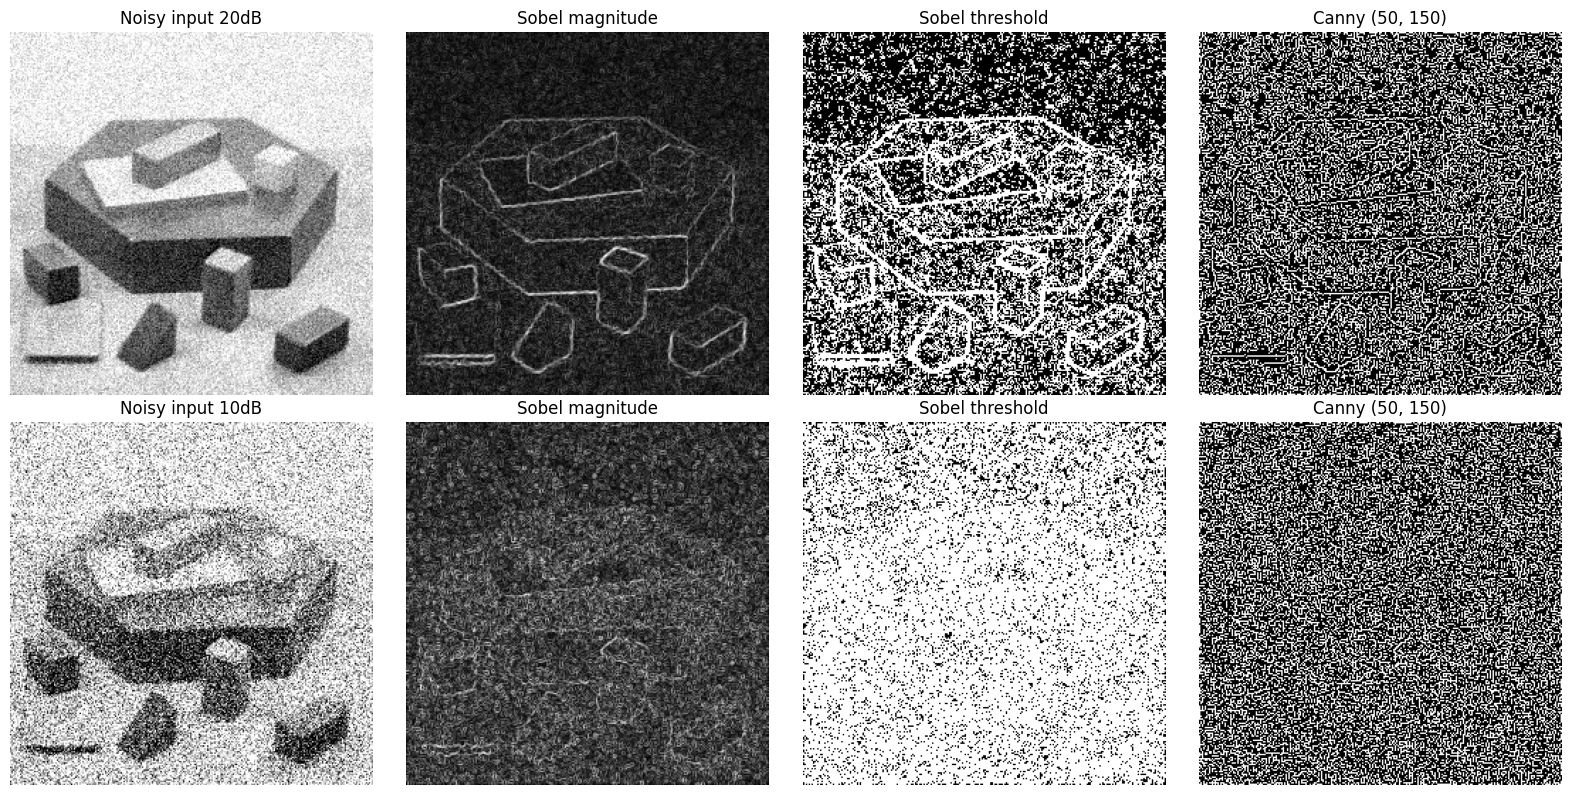

In [4]:
image_range = float(blox_gray.max() - blox_gray.min())
np.random.seed(644)
noise_images = {}
noise_edge_results = {}

for target_psnr in (20, 10):
    sigma = image_range / (10 ** (target_psnr / 20.0))
    noise = np.random.normal(0.0, sigma, size=blox_gray.shape)
    noisy_float = blox_gray.astype(np.float64) + noise
    noisy_uint8 = np.clip(np.rint(noisy_float), 0, 255).astype(np.uint8)
    measured_sigma = float(noise.std())
    measured_psnr = 20 * np.log10(image_range / measured_sigma)
    label = f"{target_psnr}dB"

    noise_images[label] = noisy_uint8
    cv2.imwrite(str(edge_output_dir / f"blox_noisy_{label}.png"), noisy_uint8)
    noise_edge_results[label] = analyze_edges(noisy_uint8)
    save_edge_result(f"blox_noisy_{label}", noise_edge_results[label])

    cov = 100 * np.count_nonzero(noise_edge_results[label]["canny"]) / noise_edge_results[label]["canny"].size
    print(
        f"{label}: target sigma={sigma:.2f}, sampled sigma={measured_sigma:.2f}, "
        f"measured PSNR={measured_psnr:.2f} dB; Canny edge coverage={cov:.1f}%"
    )

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, label in enumerate(("20dB", "10dB")):
    result = noise_edge_results[label]
    panels = [
        (noise_images[label], f"Noisy input {label}"),
        (result["magnitude"], "Sobel magnitude"),
        (result["sobel_binary"], "Sobel threshold"),
        (result["canny"], "Canny (50, 150)"),
    ]
    for axis, (pixels, title) in zip(axes[row], panels):
        axis.imshow(pixels, cmap="gray", vmin=0, vmax=255)
        axis.set_title(title)
        axis.axis("off")
plt.tight_layout()
plt.show()

### Denoising comparisons

Compare Gaussian smoothing (`cv2.GaussianBlur` with kernel sizes 3x3, 7x7, 11x11), Median filtering (`cv2.medianBlur` with sizes 3 and 7), and Bilateral filtering (`cv2.bilateralFilter` with diameter 11 and $\sigma=75$). Sobel/Canny and the intensity masks are then rerun on each denoised image using the same fixed Canny thresholds (50, 150) to evaluate how well each filter suppresses noise while retaining true object boundaries.

20dB Gaussian 3x3: Canny edge coverage 19.3%
20dB Gaussian 7x7: Canny edge coverage 4.0%
20dB Gaussian 11x11: Canny edge coverage 3.4%
20dB Median 3x3: Canny edge coverage 23.4%
20dB Median 7x7: Canny edge coverage 4.1%
20dB Bilateral d=11: Canny edge coverage 4.6%
10dB Gaussian 3x3: Canny edge coverage 38.3%
10dB Gaussian 7x7: Canny edge coverage 15.9%
10dB Gaussian 11x11: Canny edge coverage 3.6%
10dB Median 3x3: Canny edge coverage 36.1%
10dB Median 7x7: Canny edge coverage 23.3%
10dB Bilateral d=11: Canny edge coverage 36.2%


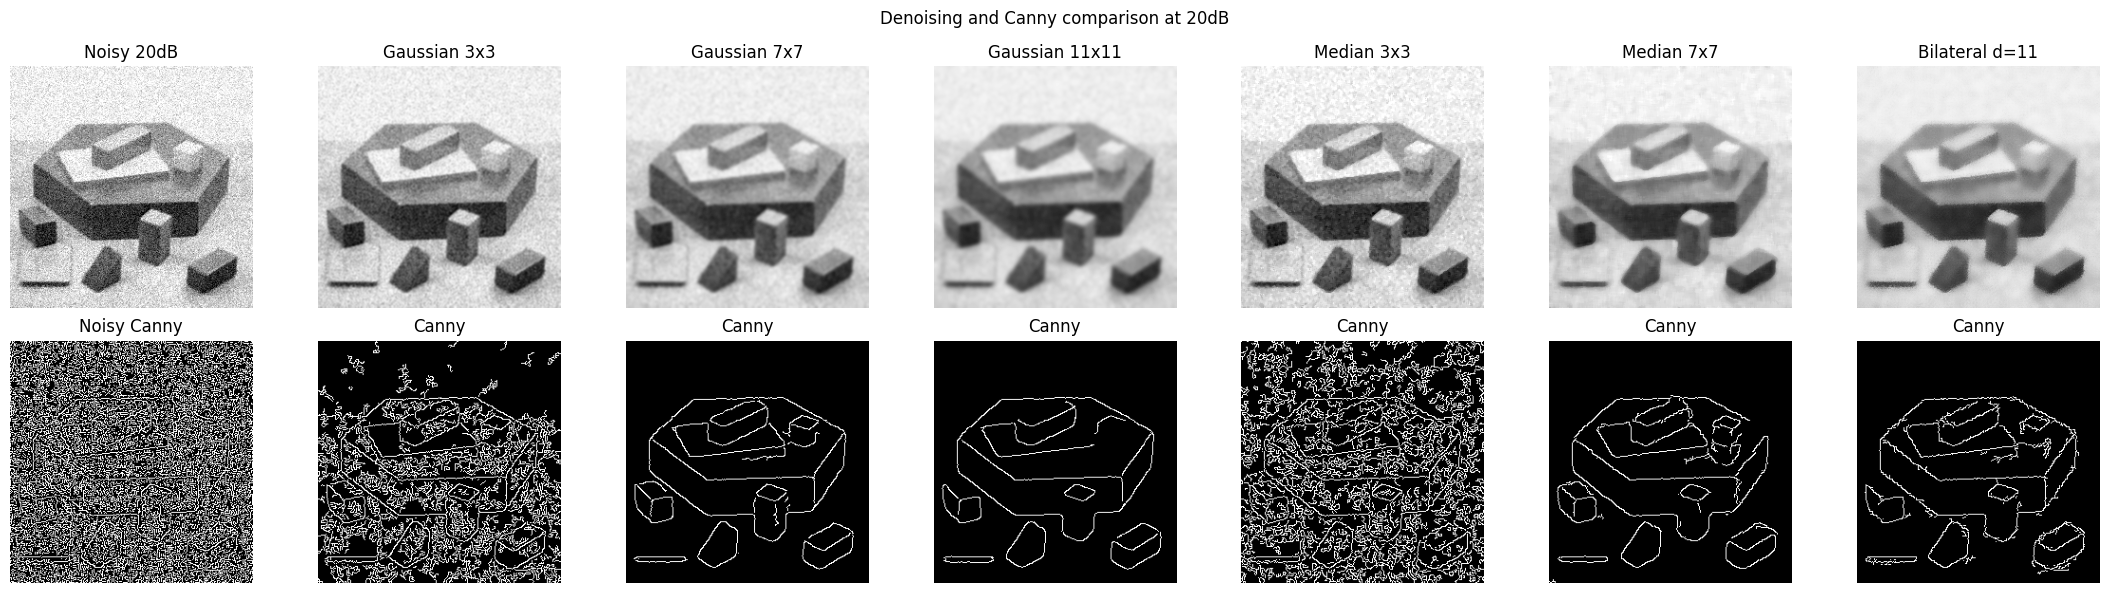

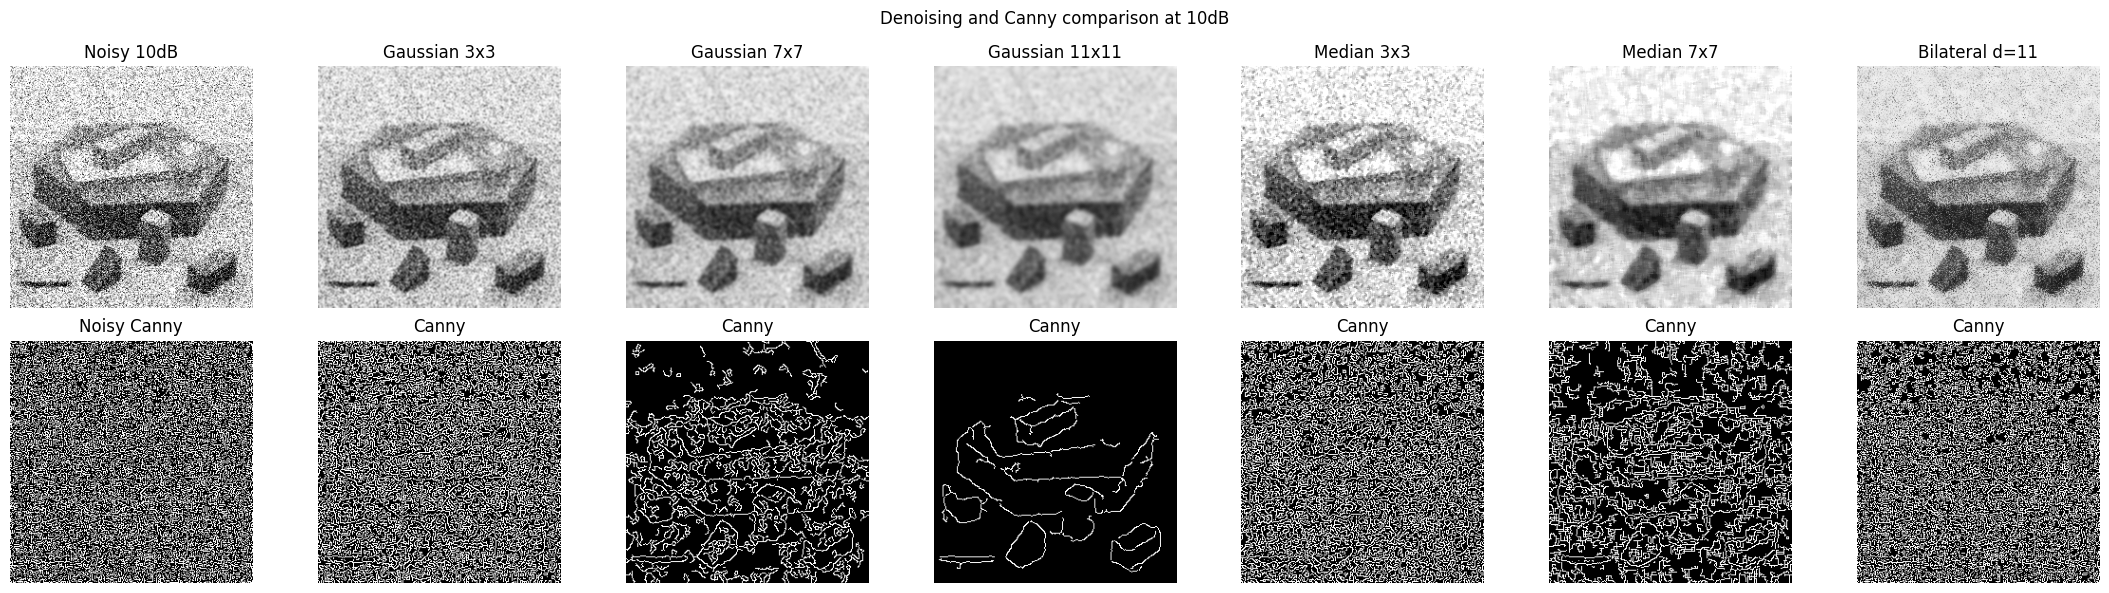

In [5]:
def denoise_image(noisy_uint8):
    """Return several denoised images using standard OpenCV filtering methods."""
    denoised = {}
    for size in (3, 7, 11):
        denoised[f"Gaussian {size}x{size}"] = cv2.GaussianBlur(
            noisy_uint8, (size, size), 0
        )
    for size in (3, 7):
        denoised[f"Median {size}x{size}"] = cv2.medianBlur(noisy_uint8, size)
    denoised["Bilateral d=11"] = cv2.bilateralFilter(
        noisy_uint8, d=11, sigmaColor=75, sigmaSpace=75
    )
    return denoised


denoised_images = {}
denoised_edge_results = {}
for label in ("20dB", "10dB"):
    denoised_images[label] = denoise_image(noise_images[label])
    denoised_edge_results[label] = {}
    for method, img in denoised_images[label].items():
        safe_method = method.lower().replace(" ", "_").replace("=", "")
        stem = f"blox_{label}_{safe_method}"
        cv2.imwrite(str(edge_output_dir / f"{stem}.png"), img)
        edge_result = analyze_edges(img)
        denoised_edge_results[label][method] = edge_result
        save_edge_result(stem, edge_result)
        coverage = 100 * np.count_nonzero(edge_result["canny"]) / edge_result["canny"].size
        print(f"{label} {method}: Canny edge coverage {coverage:.1f}%")

for label in ("20dB", "10dB"):
    methods = list(denoised_images[label])
    fig, axes = plt.subplots(2, len(methods) + 1, figsize=(3.1 * (len(methods) + 1), 6))
    axes[0, 0].imshow(noise_images[label], cmap="gray", vmin=0, vmax=255)
    axes[0, 0].set_title(f"Noisy {label}")
    axes[1, 0].imshow(noise_edge_results[label]["canny"], cmap="gray", vmin=0, vmax=255)
    axes[1, 0].set_title("Noisy Canny")
    for column, method in enumerate(methods, start=1):
        img = denoised_images[label][method]
        edge_result = denoised_edge_results[label][method]
        axes[0, column].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[0, column].set_title(method)
        axes[1, column].imshow(edge_result["canny"], cmap="gray", vmin=0, vmax=255)
        axes[1, column].set_title("Canny")
    for axis in axes.flat:
        axis.axis("off")
    fig.suptitle(f"Denoising and Canny comparison at {label}")
    plt.tight_layout()
    plt.show()

### Part 2b observations

The clean BloX image produces coherent object boundaries. Sobel magnitude shows gradient strength, while thresholding the magnitude keeps stronger gradients. Canny produces a clean, thin 1-pixel-wide edge map (5.0% coverage). The inverse threshold (<165) and inRange (60-160) outputs isolate brightness regions rather than edges.

Adding zero-mean Gaussian noise creates intense false gradients; Canny coverage jumps from 5.0% to ~35.8% at 20 dB and ~37.4% at 10 dB, heavily corrupting the edge maps.
- **Gaussian smoothing**: As kernel size increases from 3x3 to 11x11, noise edges are progressively suppressed (dropping to 4.0% and 3.4% at 20 dB, and 3.6% at 10 dB with 11x11), but heavy smoothing noticeably rounds block corners.
- **Median filtering**: Highly effective at eliminating noise spikes without blurring edges as aggressively as linear averaging. At 20 dB, a 7x7 median filter reduces false edge coverage to 4.1% while maintaining boundary clarity.
- **Bilateral filtering**: Successfully smooths flat surface faces while preserving sharp object boundaries at moderate noise (4.6% edge coverage at 20 dB). However, under severe 10 dB noise, random noise variations exceed the range parameter ($\sigma_{color}=75$), causing the filter to leave substantial residual noise (36.2% coverage).